# HR Attrition Analysis

This notebook uses the HR employee dataset to compare employees who left with those who stayed, and to examine monthly hours alongside evaluations.

## Section 1 — Prepare the data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

data_path = Path("HR_comma_sep.csv")
df = pd.read_csv(data_path).rename(
    columns={"average_montly_hours": "average_monthly_hours"}
)

print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
print("Missing values in required columns:")
print(
    df[["left", "satisfaction_level", "average_monthly_hours", "last_evaluation"]]
    .isna()
    .sum()
    .to_string()
)

Rows: 14,999; columns: 10
Missing values in required columns:
left                     0
satisfaction_level       0
average_monthly_hours    0
last_evaluation          0


In [2]:
df["employment_status"] = df["left"].map({0: "Stayed", 1: "Left"})
status_counts = df["employment_status"].value_counts().reindex(["Left", "Stayed"])
status_summary = pd.DataFrame(
    {
        "Count": status_counts,
        "Percentage": df["employment_status"]
        .value_counts(normalize=True)
        .reindex(["Left", "Stayed"])
        .mul(100),
    }
)
status_summary["Percentage"] = status_summary["Percentage"].map(lambda value: f"{value:.2f}%")
display(status_summary)

,Count,Percentage
employment_status,,
Left,3571,23.81%
Stayed,11428,76.19%


Overall, 23.81% of employees left; the denominator is all 14,999 employees.

## Section 2 — Compare satisfaction levels

Satisfaction matters to HR because it gives a practical signal of employees’ experience at work and can help identify where retention or support questions deserve a closer look.

In [3]:
satisfaction_summary = (
    df.groupby("employment_status")["satisfaction_level"]
    .agg(count="count", mean="mean", median="median", std="std")
    .reindex(["Left", "Stayed"])
)
display(satisfaction_summary.round(3))

,count,mean,median,std
employment_status,,,,
Left,3571,0.440,0.41,0.264
Stayed,11428,0.667,0.69,0.217


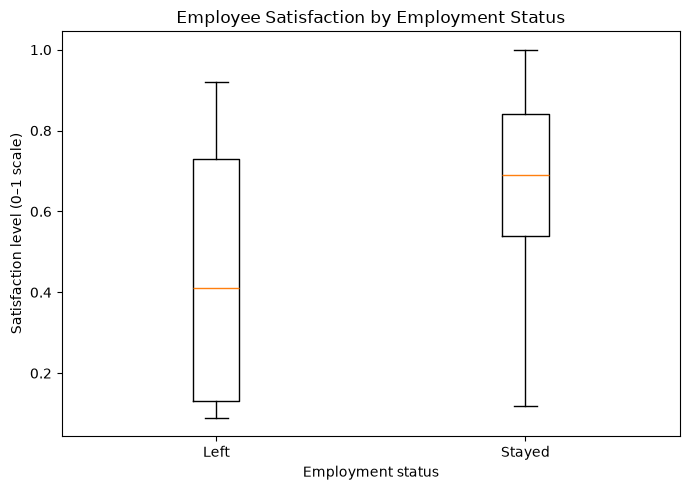

In [4]:
left_satisfaction = df.loc[
    df["employment_status"].eq("Left"), "satisfaction_level"
]
stayed_satisfaction = df.loc[
    df["employment_status"].eq("Stayed"), "satisfaction_level"
]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([left_satisfaction, stayed_satisfaction], tick_labels=["Left", "Stayed"])
ax.set_title("Employee Satisfaction by Employment Status")
ax.set_xlabel("Employment status")
ax.set_ylabel("Satisfaction level (0–1 scale)")
plt.tight_layout()
plt.show()

Employees who left had a lower median satisfaction (0.41) than employees who stayed (0.69). Satisfaction was more spread out among employees who left (standard deviation 0.264 versus 0.217), and the boxes and whiskers overlap, so the two groups are not completely separated.

## Section 3 — Welch t-test

**Null hypothesis:** The average satisfaction level is the same for employees who left and employees who stayed.

**Alternative hypothesis:** The average satisfaction level differs between employees who left and employees who stayed.

In [5]:
left_group = df.loc[df["employment_status"].eq("Left"), "satisfaction_level"]
stayed_group = df.loc[df["employment_status"].eq("Stayed"), "satisfaction_level"]
welch_result = stats.ttest_ind(left_group, stayed_group, equal_var=False)
mean_difference = left_group.mean() - stayed_group.mean()

def format_p_value(p_value):
    return "p < 1e-300" if p_value == 0 else f"{p_value:.3e}"

print(f"Mean difference (Left minus Stayed): {mean_difference:.6f}")
print(f"t statistic: {welch_result.statistic:.6f}")
print(f"p-value: {format_p_value(welch_result.pvalue)}")

Mean difference (Left minus Stayed): -0.226712
t statistic: -46.636414
p-value: p < 1e-300


At the 0.05 significance level, the result provides strong evidence against equal average satisfaction (t = −46.636, p < 1e-300). In plain language, employees who stayed had the higher mean satisfaction: 0.667 compared with 0.440 for employees who left, a difference of about 0.227 on the 0–1 scale.

## Section 4 — Hours and evaluations

Pearson r: 0.339742
p-value: p < 1e-300
r squared: 0.115424


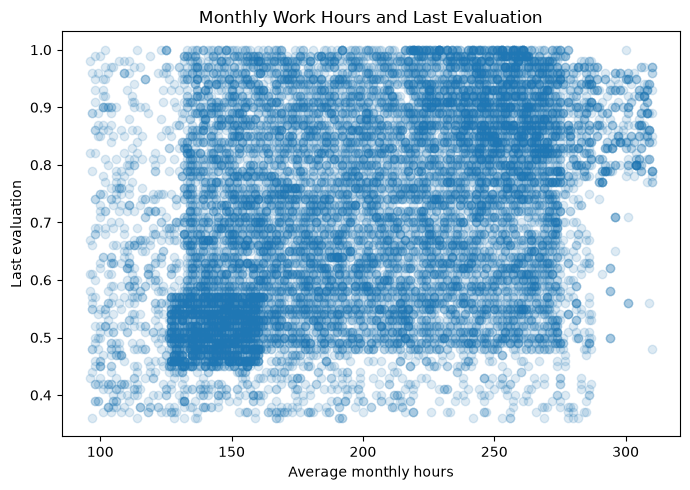

In [6]:
correlation_result = stats.pearsonr(
    df["average_monthly_hours"], df["last_evaluation"]
)
r_value = correlation_result.statistic
r_squared = r_value**2

print(f"Pearson r: {r_value:.6f}")
print(f"p-value: {format_p_value(correlation_result.pvalue)}")
print(f"r squared: {r_squared:.6f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    df["average_monthly_hours"],
    df["last_evaluation"],
    alpha=0.15,
)
ax.set_title("Monthly Work Hours and Last Evaluation")
ax.set_xlabel("Average monthly hours")
ax.set_ylabel("Last evaluation")
plt.tight_layout()
plt.show()

Employees with longer monthly hours tend to have higher evaluations: the relationship is positive (r = 0.340) and modest in strength, as the scatterplot shows a broad cloud with an upward tendency rather than a tight line. The correlation is statistically significant (p < 1e-300), but statistical significance does not mean hours are very informative for an individual employee: r² = 0.115, so hours account for about 11.5% of the variation in evaluations in this simple linear relationship. This is a correlation, not evidence that longer hours cause higher evaluations.

## Section 5 — HR briefing

Employees who left had a mean satisfaction of 0.440, compared with 0.667 for employees who stayed. Monthly hours and evaluations had a modest positive correlation (r = 0.340), with hours accounting for about 11.5% of evaluation variation in this dataset. These observational results show patterns, not causes. A useful follow-up question is whether satisfaction differences also vary by department, tenure, or workload.